### Importing libraries

In [70]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
import xgboost as xgb

In [71]:
df_train_test = pd.read_csv("data/train-test.csv")
df_train_test

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
47995,TR-047996,Reno,Baton Rouge,39.54838,-118.64843,30.50134,-92.65374,1830.9,Flatbed,31786.0,2025-10-31,0.98865,2.05626,3787.32
47996,TR-047997,Greensboro,Memphis,35.98195,-82.78379,35.56802,-89.52871,445.8,Reefer,37465.0,2025-10-31,1.03034,1.51985,1171.93
47997,TR-047998,Greensboro,Cincinnati,35.98195,-82.78379,37.15706,-86.77499,267.9,Flatbed,24528.0,2025-10-31,1.00846,1.46954,713.36
47998,TR-047999,Memphis,Reno,35.56802,-89.52871,39.54838,-118.64843,1901.3,Flatbed,37581.0,2025-10-31,1.00014,2.05132,3987.46


In [72]:
df_train_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48000 entries, 0 to 47999
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   load_id       48000 non-null  object 
 1   pickup        48000 non-null  object 
 2   delivery      48000 non-null  object 
 3   pickup_lat    48000 non-null  float64
 4   pickup_lon    48000 non-null  float64
 5   delivery_lat  48000 non-null  float64
 6   delivery_lon  48000 non-null  float64
 7   distance      48000 non-null  float64
 8   equipment     48000 non-null  object 
 9   weight        47700 non-null  float64
 10  date          48000 non-null  object 
 11  market_index  47626 non-null  float64
 12  quote_signal  48000 non-null  float64
 13  posted_rate   48000 non-null  float64
dtypes: float64(9), object(5)
memory usage: 5.1+ MB


In [73]:
df_train_test.describe()

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,market_index,quote_signal,posted_rate
count,48000.000000,48000.000000,48000.000000,48000.000000,48000.000000,47700.000000,47626.000000,48000.000000,48000.000000
mean,35.647545,-90.928964,35.641175,-90.857310,1135.856654,31028.844004,1.083387,2.062468,2373.980682
std,4.315285,13.482431,4.317199,13.476589,728.564416,9391.440620,0.168091,0.291391,1486.493245
min,28.357650,-121.698490,28.357650,-121.698490,70.000000,-47500.000000,0.676390,0.692280,57.220000
25%,31.986910,-98.400590,31.986910,-98.400590,550.400000,25800.000000,0.949670,1.891030,1251.555000
50%,35.294790,-88.089150,35.294790,-87.528710,953.300000,31436.500000,1.055800,2.055750,2030.760000
75%,39.411040,-83.285060,39.411040,-83.285060,1645.525000,37018.000000,1.219590,2.221685,3330.750000
max,44.302960,-69.500000,44.302960,-69.500000,3439.800000,47500.000000,1.467780,3.610350,25533.000000


In [74]:
df_train_test.corr(numeric_only=True)

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,market_index,quote_signal,posted_rate
pickup_lat,1.000000,0.559208,-0.008283,-0.006143,-0.077742,0.001898,-0.001735,-0.004181,-0.090873
pickup_lon,0.559208,1.000000,-0.008609,-0.012231,-0.273411,0.006603,0.001432,0.013659,-0.255058
delivery_lat,-0.008283,-0.008609,1.000000,0.557083,-0.080646,-0.004243,-0.002587,-0.002708,-0.091970
delivery_lon,-0.006143,-0.012231,0.557083,1.000000,-0.275657,-0.001144,-0.008487,0.011437,-0.257086
distance,-0.077742,-0.273411,-0.080646,-0.275657,1.000000,0.002544,-0.002181,-0.057244,0.908519
weight,0.001898,0.006603,-0.004243,-0.001144,0.002544,1.000000,-0.001331,0.008159,0.034840
market_index,-0.001735,0.001432,-0.002587,-0.008487,-0.002181,-0.001331,1.000000,-0.067827,0.034165
quote_signal,-0.004181,0.013659,-0.002708,0.011437,-0.057244,0.008159,-0.067827,1.000000,-0.039858
posted_rate,-0.090873,-0.255058,-0.091970,-0.257086,0.908519,0.034840,0.034165,-0.039858,1.000000


In [75]:
null_counts = df_train_test.isna().sum()
null_counts

load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          300
date              0
market_index    374
quote_signal      0
posted_rate       0
dtype: int64

In [76]:
# Fill with median (more robust to outliers and skewed distributions)
df_train_test['weight'] = df_train_test['weight'].fillna(df_train_test['weight'].median())
df_train_test['market_index'] = df_train_test['market_index'].fillna(df_train_test['market_index'].median())

In [77]:
null_counts = df_train_test.isna().sum()
null_counts

load_id         0
pickup          0
delivery        0
pickup_lat      0
pickup_lon      0
delivery_lat    0
delivery_lon    0
distance        0
equipment       0
weight          0
date            0
market_index    0
quote_signal    0
posted_rate     0
dtype: int64

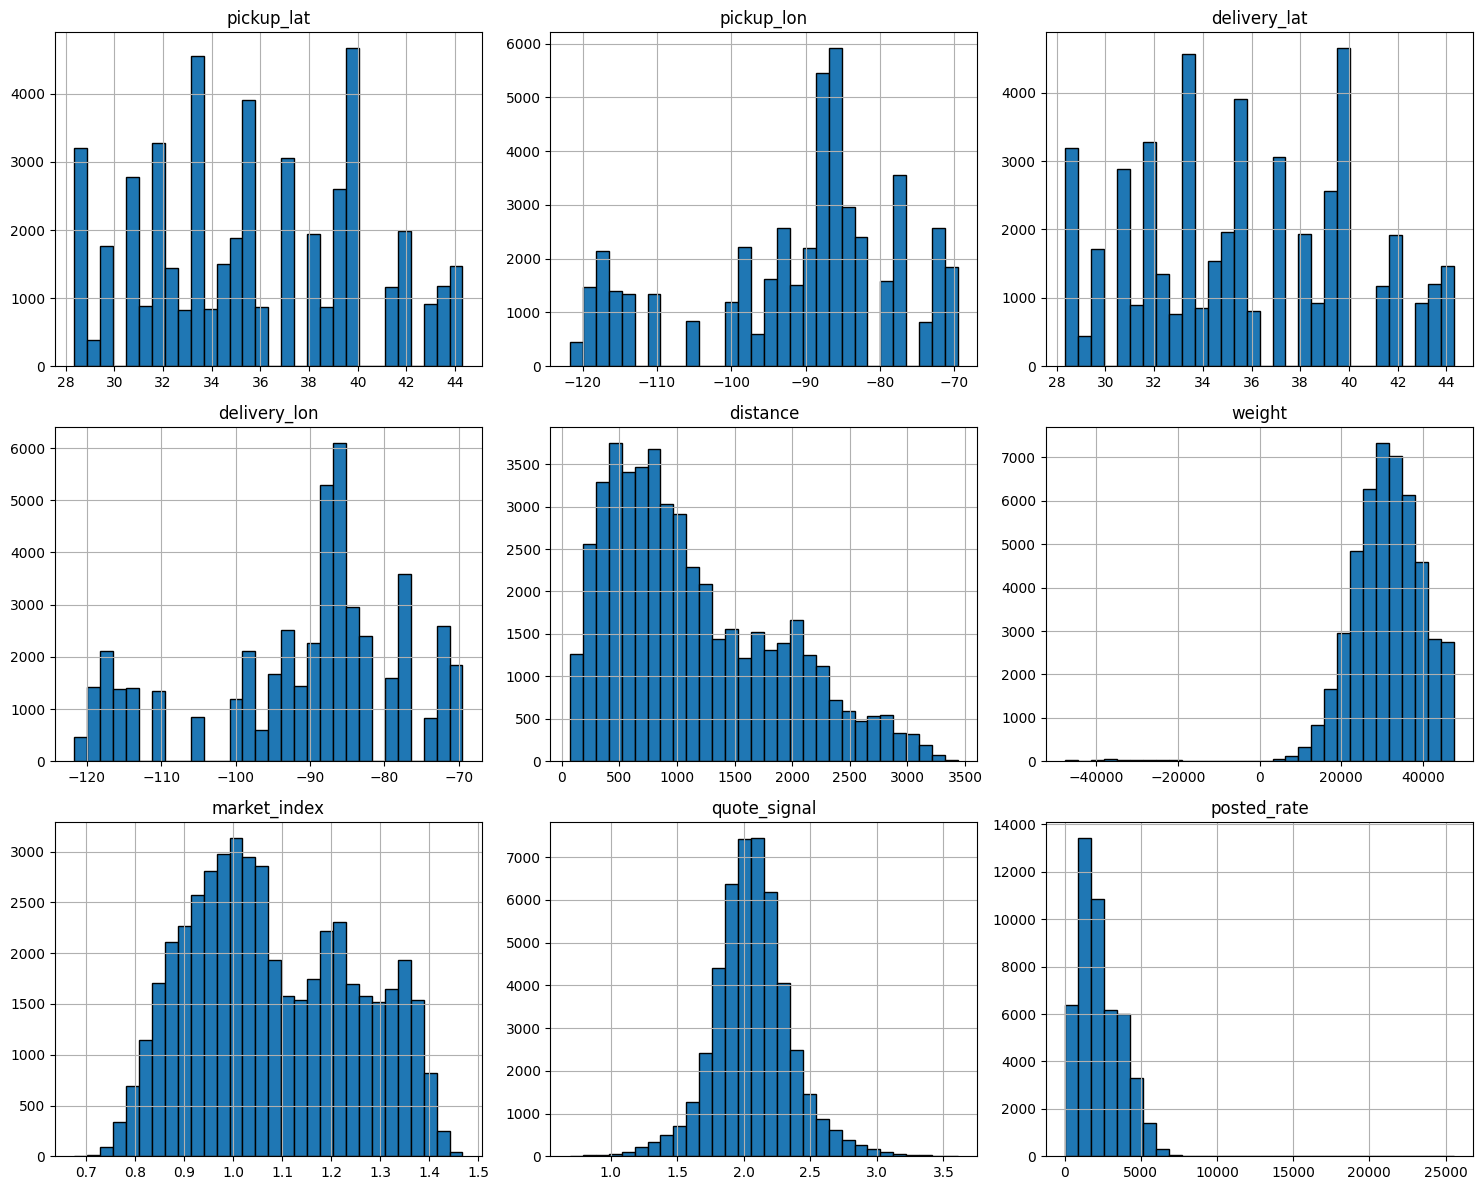

In [78]:
num_cols = df_train_test.select_dtypes(include="number").columns

df_train_test[num_cols].hist(
    bins=30,
    figsize=(15, 4 * ((len(num_cols) + 2) // 3)),
    layout = ((len(num_cols) + 2) // 3, 3),
    edgecolor='black',
)
plt.tight_layout()
plt.show()

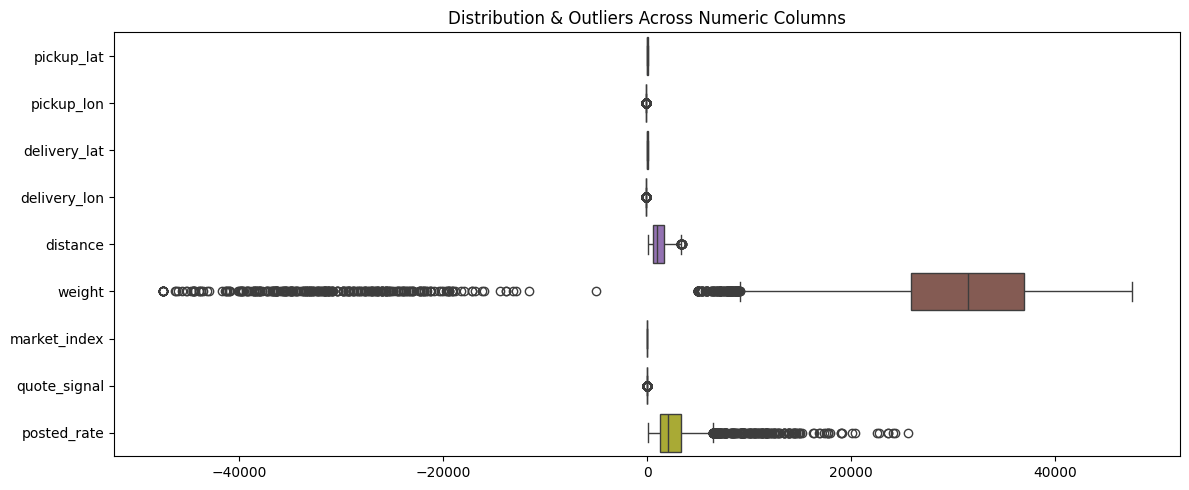

In [79]:
plt.figure(figsize=(12,5))
sns.boxplot(data=df_train_test[num_cols], orient="h")
plt.title("Distribution & Outliers Across Numeric Columns")
plt.tight_layout()
plt.show()

In [80]:
df_train_test = df_train_test.sort_values("date").reset_index(drop=True)
df_train_test.head(5)

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000094,Montgomery,Milwaukee,31.37602,-86.10743,39.62180,-88.48008,691.7,Dry Van,47500.0,2025-01-01,0.95310,2.16789,1479.61
2,TR-000095,Hartford,Madison,39.55328,-72.18051,41.70243,-89.85588,1098.0,Dry Van,29071.0,2025-01-01,0.96395,1.81827,1991.87
3,TR-000096,Hartford,Charleston,39.55328,-72.18051,34.15334,-79.74475,684.1,Dry Van,25756.0,2025-01-01,0.92209,1.90370,1297.40
4,TR-000097,Los Angeles,Reno,28.56624,-116.70249,39.54838,-118.64843,891.6,Dry Van,21332.0,2025-01-01,0.97336,1.78958,1599.62


In [81]:
df_train_test.tail(5)

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
47995,TR-047885,Green Bay,Syracuse,44.30296,-87.52871,42.80915,-76.89973,656.8,Reefer,19655.0,2025-10-31,0.99080,1.96459,1454.79
47996,TR-047886,Charleston,Columbia,34.15334,-79.74475,34.63570,-83.28506,271.0,Flatbed,42154.0,2025-10-31,0.96171,1.35623,760.70
47997,TR-047887,Montgomery,New Orleans,31.37602,-86.10743,32.53273,-92.19519,450.0,Dry Van,34391.0,2025-10-31,0.98621,1.76458,1078.09
47998,TR-047911,Charleston,Salt Lake City,34.15334,-79.74475,35.03488,-113.18895,2182.6,Dry Van,26735.0,2025-10-31,0.99746,2.24777,4081.47
47999,TR-048000,Bakersfield,Baltimore,33.28832,-116.67935,38.16908,-72.74564,2860.4,Dry Van,28359.0,2025-10-31,1.07073,2.31578,5264.84


In [82]:
ts = pd.to_datetime(df_train_test["date"])

# True if every single timestamp is identical
all_same = ts.nunique(dropna=False) <= 1
print("Exact timestamp same:", all_same)

Exact timestamp same: False


In [83]:
# Or check on calendar-day level only (ignoring hours/minutes/seconds)
all_same_day = ts.dt.date.nunique(dropna=False) <= 1
print("Calendar day same:", all_same_day)

Calendar day same: False


In [84]:
df_train_test["date"] = pd.to_datetime(df_train_test["date"])

In [85]:
df_train_test = df_train_test.sort_values("date").reset_index(drop=True)
df_train_test.head(5)

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [86]:
df_train_test.tail(5)

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
47995,TR-047997,Greensboro,Memphis,35.98195,-82.78379,35.56802,-89.52871,445.8,Reefer,37465.0,2025-10-31,1.03034,1.51985,1171.93
47996,TR-047913,Louisville,Cincinnati,37.36588,-87.47153,37.15706,-86.77499,72.8,Flatbed,33190.0,2025-10-31,0.96197,1.06068,225.89
47997,TR-047990,Dayton,Madison,39.87206,-85.62931,41.70243,-89.85588,314.9,Reefer,38185.0,2025-10-31,0.97425,1.45754,855.05
47998,TR-047912,Hartford,Columbia,39.55328,-72.18051,34.63570,-83.28506,844.4,Dry Van,45167.0,2025-10-31,0.98418,2.04428,1776.62
47999,TR-048000,Bakersfield,Baltimore,33.28832,-116.67935,38.16908,-72.74564,2860.4,Dry Van,28359.0,2025-10-31,1.07073,2.31578,5264.84


In [87]:
start_date = df_train_test['date'].min()
end_date = df_train_test['date'].max()
duration = end_date - start_date

print(f"Range: {start_date} -> {end_date}")
print(f"Span: {duration.days} days")

Range: 2025-01-01 00:00:00 -> 2025-10-31 00:00:00
Span: 303 days


Train - test validation, without data leakage

In [88]:
drop_cols = ['posted_rate', 'load_id', 'date','pickup','delivery']

df_features = df_train_test.copy()

df_features['date'] = pd.to_datetime(df_features['date'])
df_features['month'] = df_features['date'].dt.month
df_features['day'] = df_features['date'].dt.day
df_features['dayofweek'] = df_features['date'].dt.dayofweek

# Convert 'equipment' ('Dry Van', 'Reefer','Flatbed) into 0/1 columns
df_features = pd.get_dummies(df_features, columns=['equipment'], drop_first=True)

X = df_features.drop(columns=drop_cols)
y = df_features['posted_rate']
X.head()


,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,market_index,quote_signal,month,day,dayofweek,equipment_Flatbed,equipment_Reefer
0,38.09122,-76.78906,38.16908,-72.74564,274.3,30658.0,0.95684,2.39595,1,1,2,False,False
1,38.09122,-76.78906,39.22317,-72.96710,280.5,17555.0,0.97623,2.43355,1,1,2,False,True
2,39.22317,-72.96710,44.30296,-87.52871,967.8,31721.0,1.00971,1.84491,1,1,2,False,False
3,39.55328,-72.18051,34.84933,-86.28940,965.4,32333.0,0.94518,1.87712,1,1,2,False,False
4,31.83025,-94.38343,35.29479,-88.08915,541.9,35183.0,0.98480,2.56300,1,1,2,False,True


In [89]:
split_idx = int(len(df_train_test) * 0.8)
X_train, X_valid = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_valid = y.iloc[:split_idx], y.iloc[split_idx:]



### Feature Importance

In [90]:
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [91]:
importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(importances)

distance             0.865634
quote_signal         0.032812
market_index         0.021833
weight               0.021436
day                  0.008433
pickup_lat           0.007777
delivery_lat         0.007607
delivery_lon         0.007263
pickup_lon           0.006640
month                0.006205
equipment_Reefer     0.005949
dayofweek            0.005419
equipment_Flatbed    0.002990
dtype: float64


In [92]:
from sklearn.metrics import mean_absolute_error
tscv = TimeSeriesSplit(n_splits=5)

fold_metrics = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X)):
    X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
    X_valid, y_valid = X.iloc[val_idx], y.iloc[val_idx]
    # Initialize and fit
    rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)

    # Predict on out-of-time validation fold
    y_pred = rf.predict(X_valid)

    mae = mean_absolute_error(y_valid, y_pred)
    rmse = root_mean_squared_error(y_valid, y_pred)
    r2 = r2_score(y_valid, y_pred)    

    fold_metrics.append({
        'Fold': fold + 1,
        'Train Size': len(X_train),
        'Val Size': len(X_valid),
        'MAE ($)': round(mae, 2),
        'RMSE ($)': round(rmse, 2),
        'R2': round(r2, 4)
    })
    print(f"Fold {fold + 1} | Train: {len(X_train):,} rows | Val: {len(X_valid):,} rows | MAE: ${mae:.2f} | RMSE: ${rmse:.2f} | R²: {r2:.4f}")

# Summary Table
cv_results = pd.DataFrame(fold_metrics)
print("\n--- Cross-Validation Summary ---")
print(cv_results)
print(f"\nMean MAE:  ${cv_results['MAE ($)'].mean():.2f}")
print(f"Mean RMSE: ${cv_results['RMSE ($)'].mean():.2f}")
print(f"Mean R²:   {cv_results['R2'].mean():.4f}")

Fold 1 | Train: 8,000 rows | Val: 8,000 rows | MAE: $254.43 | RMSE: $810.48 | R²: 0.6728
Fold 2 | Train: 16,000 rows | Val: 8,000 rows | MAE: $153.90 | RMSE: $610.04 | R²: 0.8346
Fold 3 | Train: 24,000 rows | Val: 8,000 rows | MAE: $166.03 | RMSE: $690.49 | R²: 0.8016
Fold 4 | Train: 32,000 rows | Val: 8,000 rows | MAE: $194.36 | RMSE: $668.98 | R²: 0.7996
Fold 5 | Train: 40,000 rows | Val: 8,000 rows | MAE: $178.68 | RMSE: $696.20 | R²: 0.7953

--- Cross-Validation Summary ---
   Fold  Train Size  Val Size  MAE ($)  RMSE ($)      R2
0     1        8000      8000   254.43    810.48  0.6728
1     2       16000      8000   153.90    610.04  0.8346
2     3       24000      8000   166.03    690.49  0.8016
3     4       32000      8000   194.36    668.98  0.7996
4     5       40000      8000   178.68    696.20  0.7953

Mean MAE:  $189.48
Mean RMSE: $695.24
Mean R²:   0.7808


### XGBoost using

In [93]:
from sklearn.metrics import mean_absolute_error
tscv = TimeSeriesSplit(n_splits=5)

fold_metrics = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X)):
    X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
    X_valid, y_valid = X.iloc[val_idx], y.iloc[val_idx]

    # Initialize XGBoost Regressor
    model_xgb = xgb.XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    )

    # Train
    model_xgb.fit(
        X_train, y_train,
        eval_set=[(X_valid, y_valid)])

    # Predict on out-of-time validation fold
    y_pred = model_xgb.predict(X_valid)

    mae = mean_absolute_error(y_valid, y_pred)
    rmse = root_mean_squared_error(y_valid, y_pred)
    r2 = r2_score(y_valid, y_pred)    

    fold_metrics.append({
        'Fold': fold + 1,
        'Train Size': len(X_train),
        'Val Size': len(X_valid),
        'MAE ($)': round(mae, 2),
        'RMSE ($)': round(rmse, 2),
        'R2': round(r2, 4)
    })
    print(f"Fold {fold + 1} | Train: {len(X_train):,} rows | Val: {len(X_valid):,} rows | MAE: ${mae:.2f} | RMSE: ${rmse:.2f} | R²: {r2:.4f}")

# Summary Table
cv_results = pd.DataFrame(fold_metrics)
print("\n--- XGBoost Cross-Validation Summary ---")
print(cv_results)
print(f"\nMean MAE:  ${cv_results['MAE ($)'].mean():.2f}")
print(f"Mean RMSE: ${cv_results['RMSE ($)'].mean():.2f}")
print(f"Mean R²:   {cv_results['R2'].mean():.4f}")

[0]	validation_0-rmse:1354.63545
[1]	validation_0-rmse:1295.11729
[2]	validation_0-rmse:1242.18543
[3]	validation_0-rmse:1185.91791
[4]	validation_0-rmse:1134.59824
[5]	validation_0-rmse:1091.67600
[6]	validation_0-rmse:1043.30457
[7]	validation_0-rmse:1002.16711
[8]	validation_0-rmse:963.40313
[9]	validation_0-rmse:932.66905
[10]	validation_0-rmse:900.42314
[11]	validation_0-rmse:868.15321
[12]	validation_0-rmse:836.59304
[13]	validation_0-rmse:808.16927
[14]	validation_0-rmse:783.28237
[15]	validation_0-rmse:771.06638
[16]	validation_0-rmse:749.49277
[17]	validation_0-rmse:732.53260
[18]	validation_0-rmse:712.31464
[19]	validation_0-rmse:696.53065
[20]	validation_0-rmse:683.98226
[21]	validation_0-rmse:670.86295
[22]	validation_0-rmse:657.73800
[23]	validation_0-rmse:648.06781
[24]	validation_0-rmse:638.37824
[25]	validation_0-rmse:629.15912
[26]	validation_0-rmse:623.14189
[27]	validation_0-rmse:617.06555
[28]	validation_0-rmse:617.08319
[29]	validation_0-rmse:613.64802
[30]	validat

In [95]:
# Train Final XGBoost Model on 100% of Data
final_xgb = xgb.XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)
final_xgb.fit(X, y)
print("Final XGBoost model trained on all 48,000 rows!")

Final XGBoost model trained on all 48,000 rows!


In [96]:
df_val = pd.read_csv('data/validation.csv')

# 2. Impute missing values using training medians
df_val['weight'] = df_val['weight'].fillna(df_train_test['weight'].median())
df_val['market_index'] = df_val['market_index'].fillna(df_train_test['market_index'].median())

# 3. Create same date & equipment features
df_val_feat = df_val.copy()
df_val_feat['date'] = pd.to_datetime(df_val_feat['date'])
df_val_feat['month'] = df_val_feat['date'].dt.month
df_val_feat['day'] = df_val_feat['date'].dt.day
df_val_feat['dayofweek'] = df_val_feat['date'].dt.dayofweek
df_val_feat = pd.get_dummies(df_val_feat, columns=['equipment'], drop_first=True, dtype=int)

# 4. Align feature columns to match X exactly
X_val_final = df_val_feat[X.columns].astype(float)
# 5. Predict with final_xgb
df_val['predicted_rate'] = final_xgb.predict(X_val_final)
# 6. Save as required: exactly two columns: load_id, predicted_rate
submission = df_val[['load_id', 'predicted_rate']]
submission.to_csv('validation_predictions.csv', index=False)
print(f"✅ Saved validation_predictions.csv with {len(submission):,} rows!")

✅ Saved validation_predictions.csv with 12,000 rows!


In [97]:
# 1. Load December inputs
df_dec = pd.read_csv('data/december-chart-inputs.csv')
# 2. Map coordinates for Lexington and Fort Wayne
df_dec['pickup_lat'] = 36.99152
df_dec['pickup_lon'] = -84.99876
df_dec['delivery_lat'] = 41.31561
df_dec['delivery_lon'] = -85.36206

# 3. Merge daily market signals from validation set
daily_signals = df_val.groupby('date')[['market_index', 'quote_signal']].mean().reset_index()
df_dec = df_dec.merge(daily_signals, on='date', how='left')

# 4. Date features & equipment dummies
df_dec['date'] = pd.to_datetime(df_dec['date'])
df_dec['month'] = df_dec['date'].dt.month
df_dec['day'] = df_dec['date'].dt.day
df_dec['dayofweek'] = df_dec['date'].dt.dayofweek
df_dec['equipment_Flatbed'] = 0
df_dec['equipment_Reefer'] = 0

# 5. Predict
X_dec = df_dec[X.columns].astype(float)
df_dec['predicted_rate'] = final_xgb.predict(X_dec)

# 6. Overwrite data/december-chart-inputs.csv with the predicted_rate filled
output_cols = ['pickup', 'delivery', 'distance', 'equipment', 'weight', 'date', 'predicted_rate']
df_dec[output_cols].to_csv('data/december-chart-inputs.csv', index=False)
print("✅ Saved data/december-chart-inputs.csv!")

✅ Saved data/december-chart-inputs.csv!
